In [1]:
import cosmic
from cosmic.output import load_initC
import h5py as h5
import os
import pandas as pd
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from importlib import reload
from astropy.coordinates import SkyCoord
import seaborn as sns
from astropy.constants import G
from copy import copy

import legwork as lw
import gala.potential as gp
import cogsworth

import sys
sys.path.append("../helpers")

import detections
import const
import plotting
import uncertainties as unc

plt.rc('font', family='serif')
plt.rcParams['text.usetex'] = False
fs = 24

# update various fontsizes to match
params = {'figure.figsize': (12, 8),
          'legend.fontsize': 0.7*fs,
          'legend.title_fontsize': 0.8*fs,
          'axes.labelsize': fs,
          'xtick.labelsize': 0.9 * fs,
          'ytick.labelsize': 0.9 * fs,
          'axes.linewidth': 1.1,
          'xtick.major.size': 7,
          'xtick.minor.size': 4,
          'ytick.major.size': 7,
          'ytick.minor.size': 4,
          'xtick.minor.visible': True,
          'ytick.minor.visible': True,}
plt.rcParams.update(params)

pd.set_option('display.max_columns', None)

%config InlineBackend.figure_format = 'retina'

# Load data

In [2]:
dco_types = ["NSWD", "BHWD"]
dco_types = [d + "_pessimistic" for d in dco_types]

In [3]:
pops = {
    dco_type: cogsworth.pop.load(f"/mnt/ceph/users/twagg/lisa-dcos/fiducial/{dco_type}_in_band.h5") for dco_type in dco_types
}

In [4]:
for dco_type in dco_types:
    pop = pops[dco_type]
    print(dco_type)
    pop.final_pos, pop.final_vel

NSWD_pessimistic
BHWD_pessimistic


In [5]:
detectable_pops = {}
for dco_type in dco_types:
    mask = (
        (pops[dco_type].bpp["snr_lisa_8yr_final_pos"] > 12)
        | (pops[dco_type].bpp["snr_lisa_8yr_initial_pos"] > 12)
        | (pops[dco_type].bpp["snr_decigo_8yr_final_pos"] > 12)
        | (pops[dco_type].bpp["snr_decigo_8yr_initial_pos"] > 12)
    )
    detectable_pops[dco_type] = pops[dco_type][mask]

cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


cogsworth warning: You've just masked a population that wasn't fully loaded from a file. This means that the masked population won't have access to the parts that were not loaded. If you don't need the missing parts then this is fine, for reference those are: ['orbits'].


In [6]:
detectable_sources = {}
for dco_type in dco_types:
    print(dco_type)
    path = f"/mnt/ceph/users/twagg/lisa-dcos/fiducial/{dco_type}_detectable_sources.h5"
    if os.path.isfile(path):
        detectable_sources[dco_type] = lw.source.Source.from_file(path)
    else:
        # turn them into a LEGWORK source class
        detectable_sources[dco_type] = detectable_pops[dco_type].to_legwork_sources(assume_mw_galactocentric=True)
        detectable_sources[dco_type].n_proc = 30

        # find those that haven't reached RLOF yet evolve them via GWs until present day
        if "rlof_time" not in detectable_pops[dco_type].bpp.columns:
             detectable_pops[dco_type].bpp["rlof_time"] = 1e20

        reached_rlof = detectable_pops[dco_type].initial_galaxy.tau > detectable_pops[dco_type].bpp["rlof_time"].values * u.Myr

        non_rlof_sources = detectable_sources[dco_type][~reached_rlof]
        non_rlof_sources.evolve_sources(t_evol=detectable_pops[dco_type].initial_galaxy.tau[~reached_rlof] - detectable_pops[dco_type].bpp["tphys"].values[~reached_rlof] * u.Myr)

        # recombine into a single source class
        detectable_sources[dco_type].m_1[~reached_rlof] = non_rlof_sources.m_1
        detectable_sources[dco_type].m_2[~reached_rlof] = non_rlof_sources.m_2
        detectable_sources[dco_type].dist[~reached_rlof] = non_rlof_sources.dist
        detectable_sources[dco_type].ecc[~reached_rlof] = non_rlof_sources.ecc
        detectable_sources[dco_type].f_orb[~reached_rlof] = non_rlof_sources.f_orb
        detectable_sources[dco_type].merged[~reached_rlof] = non_rlof_sources.merged

        detectable_sources[dco_type].save(path, overwrite=True)

NSWD_pessimistic
BHWD_pessimistic


In [7]:
lisa_pops = {dco_type: detectable_pops[dco_type + "_pessimistic"][detectable_pops[dco_type + "_pessimistic"].bpp["snr_lisa_8yr_final_pos"] > 12] for dco_type in const.DCO_TYPES if "WD" in dco_type}
lisa_sources = {dco_type: detectable_sources[dco_type + "_pessimistic"][detectable_pops[dco_type + "_pessimistic"].bpp["snr_lisa_8yr_final_pos"] > 12] for dco_type in const.DCO_TYPES if "WD" in dco_type}

[ 31.43145634 155.44955064 557.62805376]


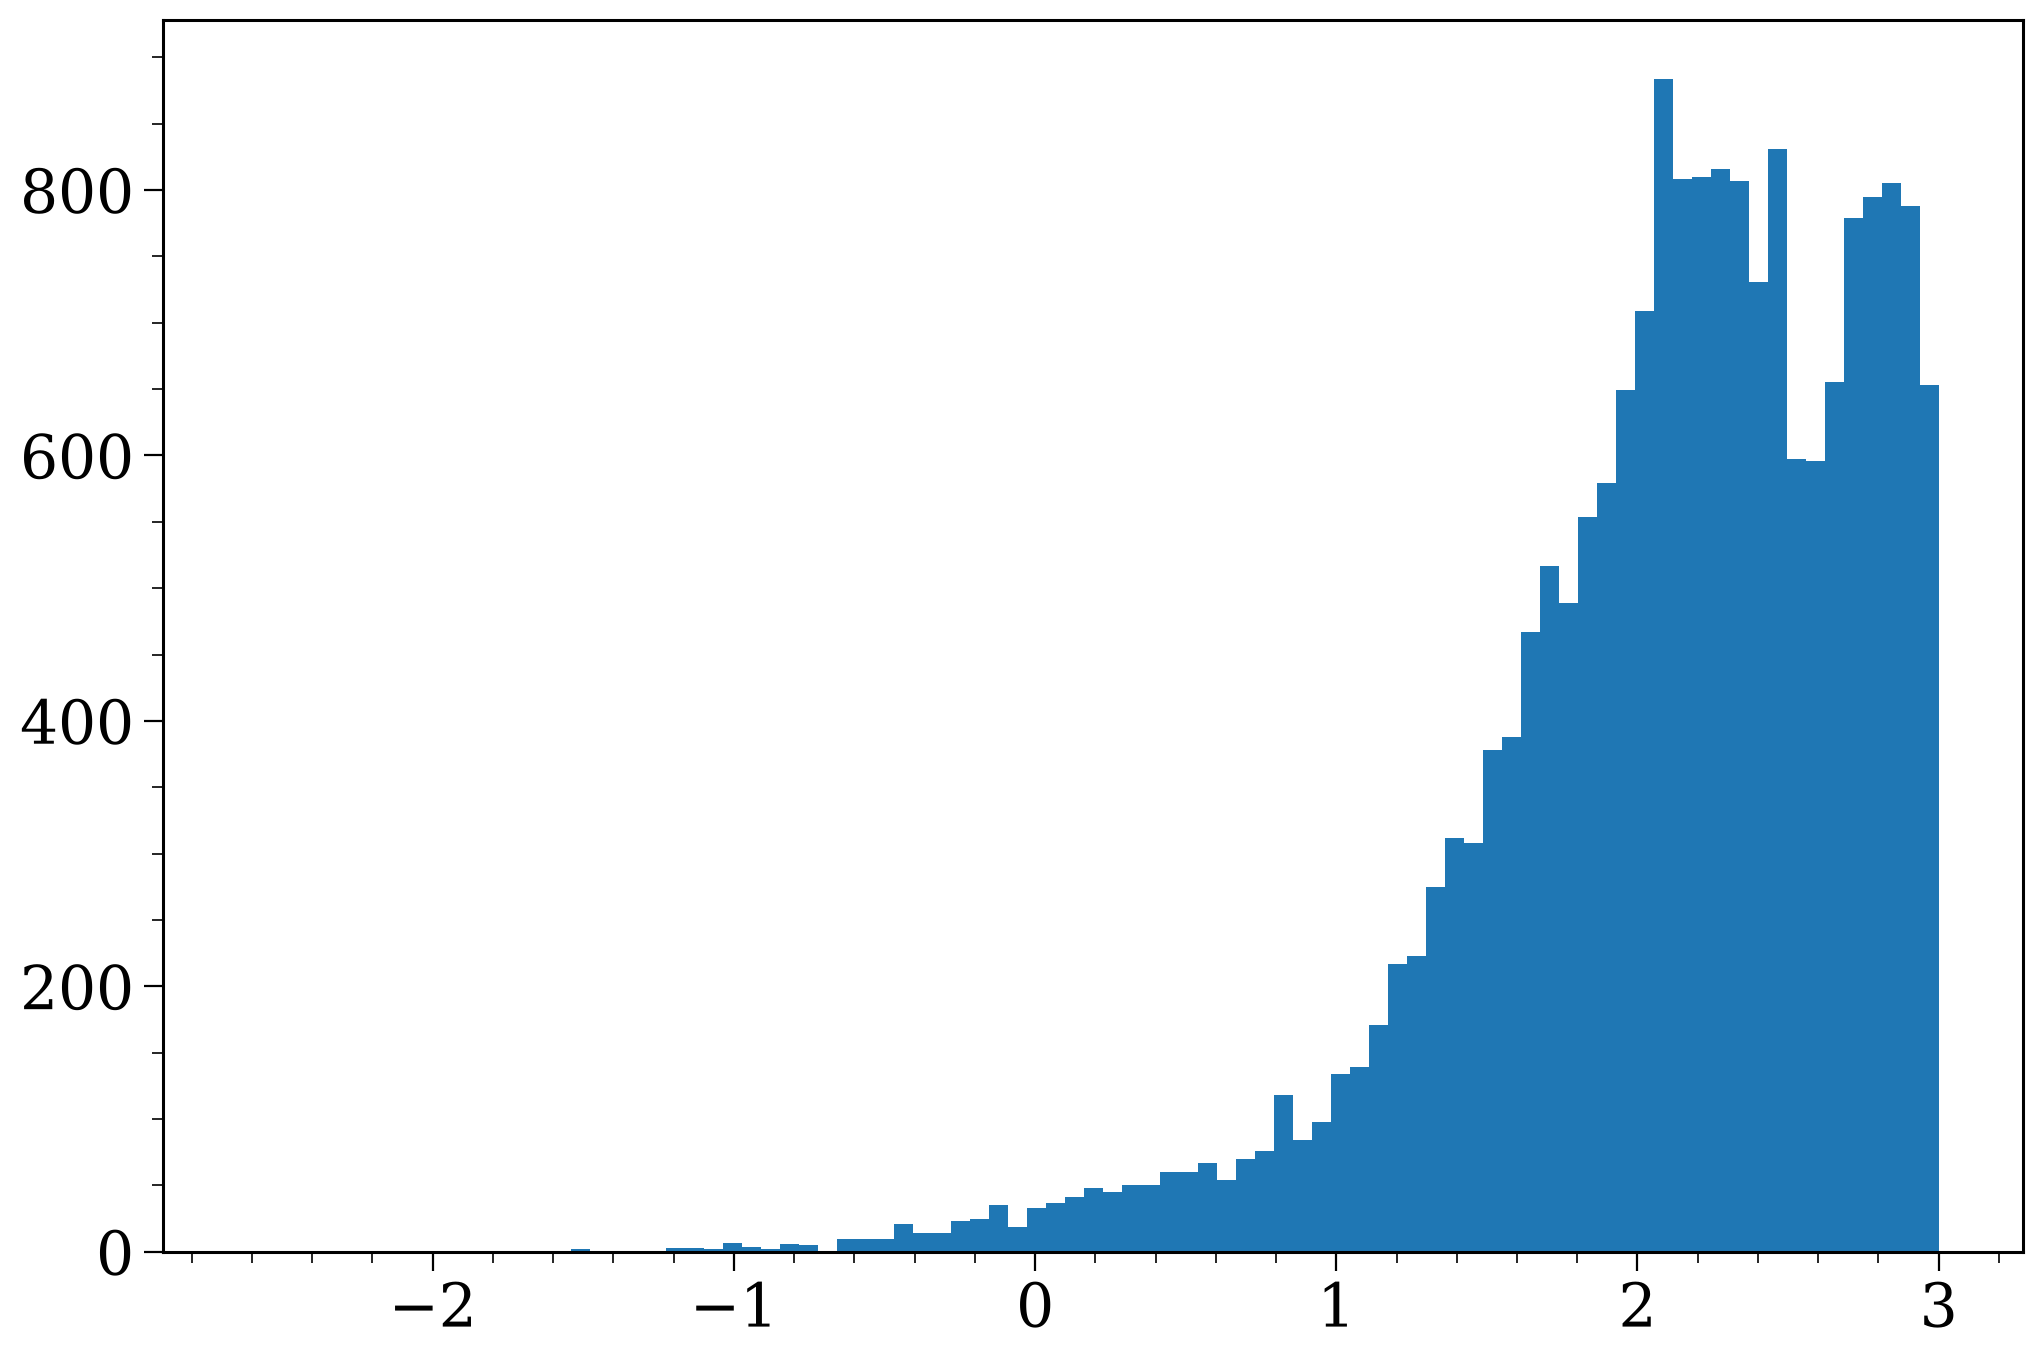

[0.59176413 2.0279549  7.66040303]


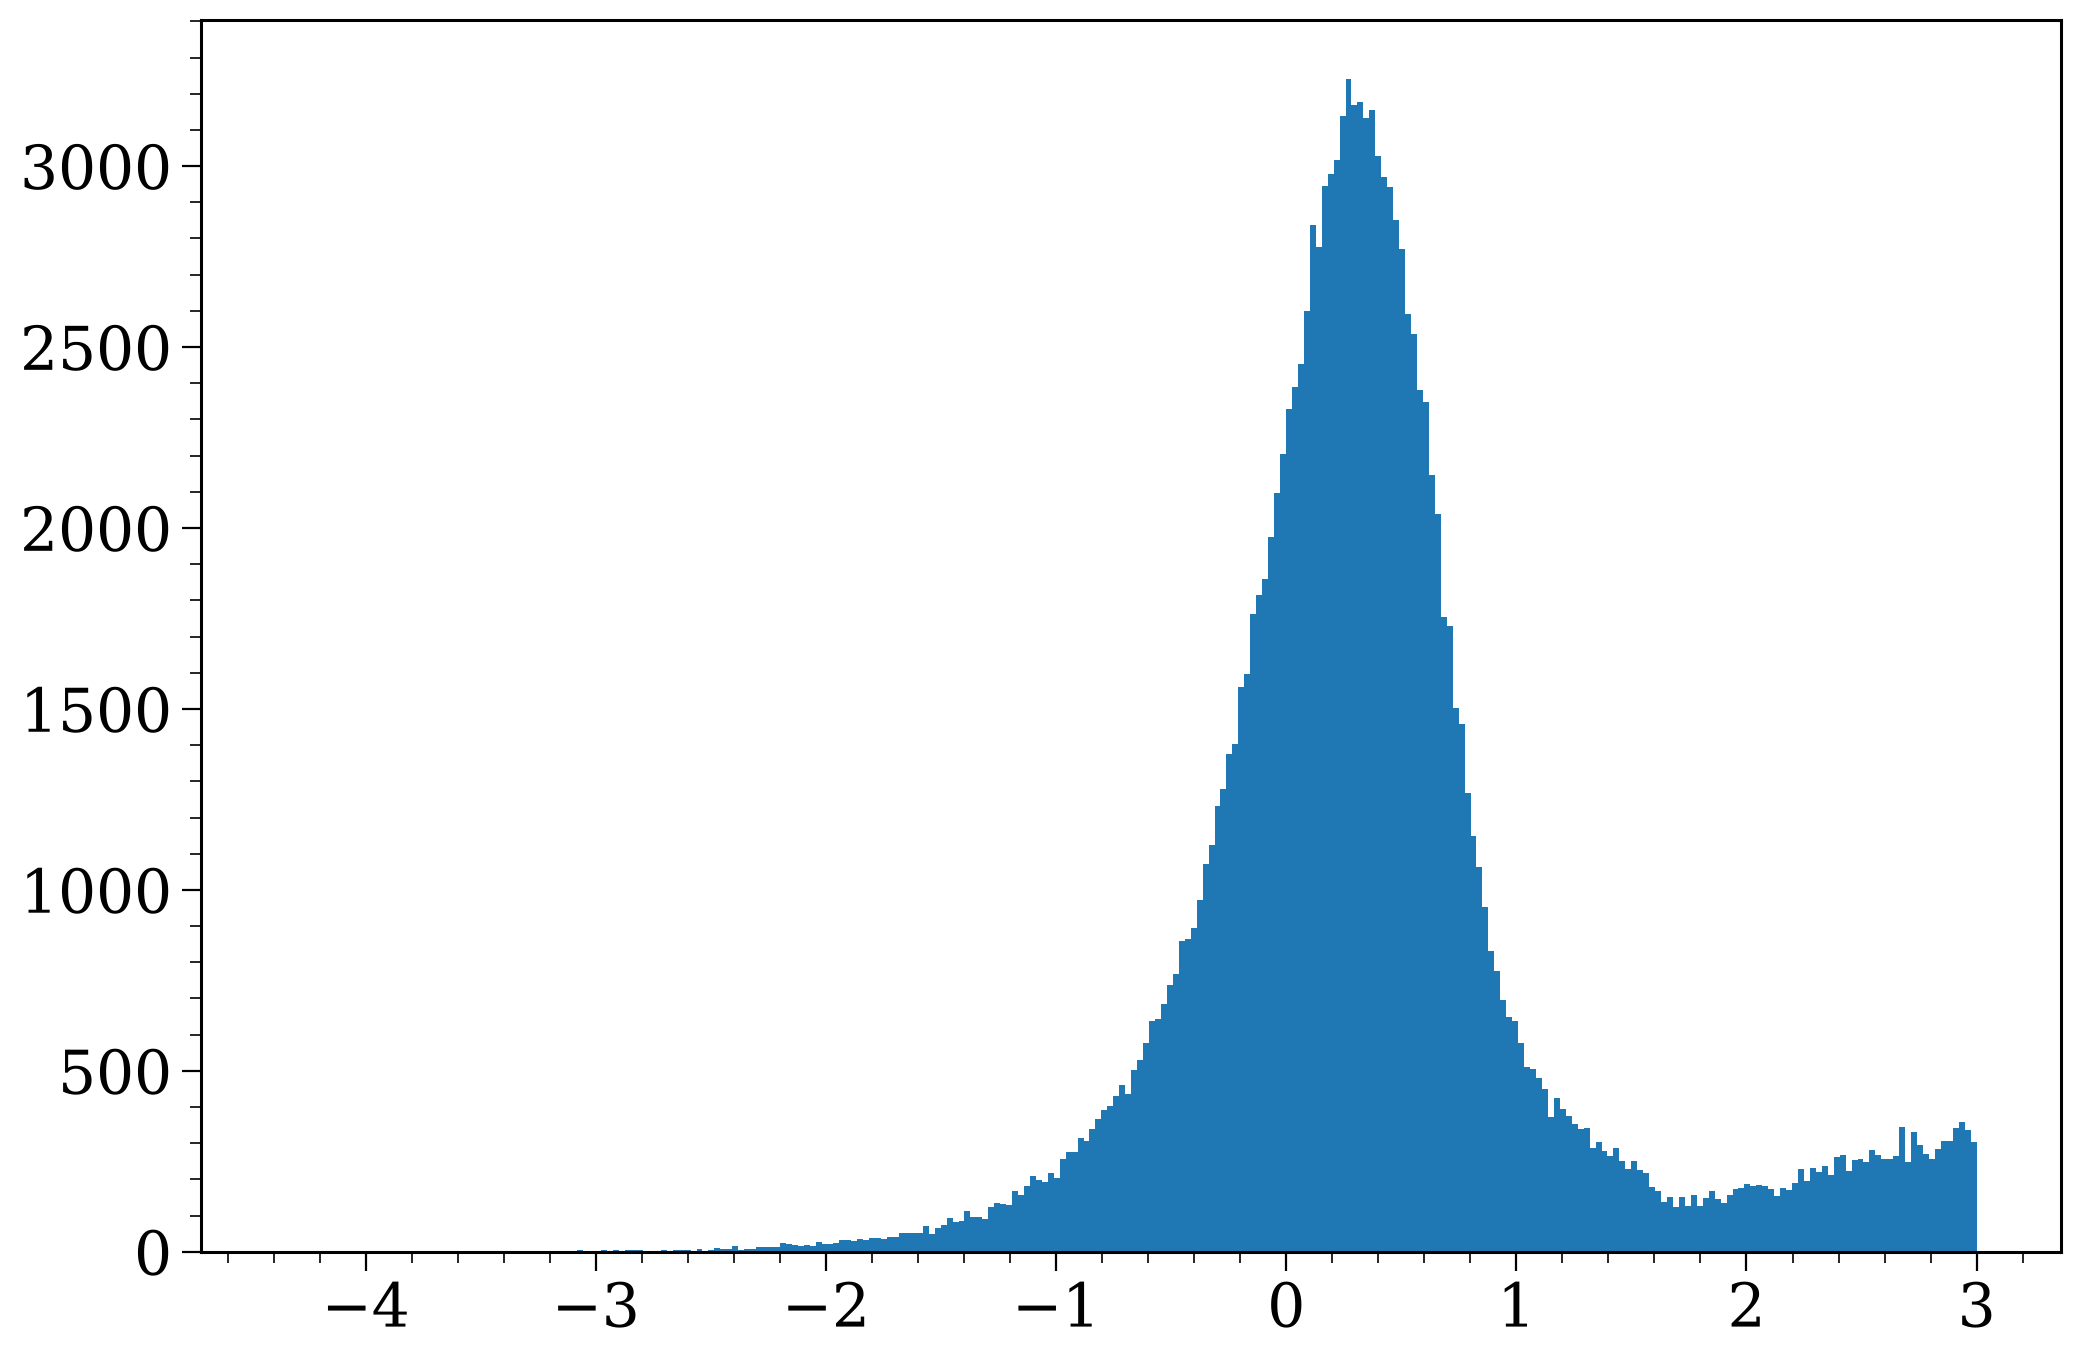

In [8]:
for dco_type in lisa_pops:
    time_since_rlof = lisa_pops[dco_type].initial_galaxy.tau - lisa_pops[dco_type].bpp["rlof_time"].values * u.Myr
    time_since_rlof_pos = time_since_rlof[time_since_rlof > 0]
    plt.hist(np.log10(time_since_rlof_pos.to(u.Myr).value), bins="fd")
    print(np.percentile(time_since_rlof_pos.to(u.Myr).value, [16, 50, 84]))
    # plt.scatter(np.log10(time_since_rlof_pos.to(u.Myr).value), lisa_sources[dco_type].m_1[time_since_rlof > 0], color=const.DCO_COLOURS[dco_type], s=1)
    plt.show()

In [9]:
rlof_pops = {}
rlof_sources = {}
for dco_type in lisa_pops:

    
    print(dco_type)
    print(len(lisa_pops[dco_type]))

    reached_rlof = lisa_pops[dco_type].initial_galaxy.tau > lisa_pops[dco_type].bpp["rlof_time"].values * u.Myr
    print(reached_rlof.sum(), "reached RLOF")
    print(lisa_pops[dco_type].bpp["weights"][reached_rlof].sum() / lisa_pops[dco_type].bpp["weights"].sum(), "fraction of total weight that reached RLOF")

    rlof_pops[dco_type] = lisa_pops[dco_type][reached_rlof]
    rlof_sources[dco_type] = lisa_sources[dco_type][reached_rlof]

    # pick a random sample of 20,000 sources if there are more than that
    if len(rlof_sources[dco_type]) > 20000:
        rand_sample = np.random.choice(rlof_pops[dco_type].bin_nums, size=20_000, replace=False)
        rand_mask = np.isin(rlof_pops[dco_type].bin_nums, rand_sample)
        rlof_pops[dco_type] = rlof_pops[dco_type][rand_mask]
        rlof_sources[dco_type] = rlof_sources[dco_type][rand_mask]
        print("Reduced to 20,000 sources for plotting")

BHWD
104448
19081 reached RLOF
0.2067317566580438 fraction of total weight that reached RLOF
NSWD
225066
145559 reached RLOF
0.6360670444657255 fraction of total weight that reached RLOF
Reduced to 20,000 sources for plotting


In [10]:
bcms = {}
bpps = {}

for dco_type in rlof_pops:
    print(rlof_pops[dco_type])
    # create a new initC based on the initC, but using the present day masses, kstars, sep, eccentricity

    initC = rlof_pops[dco_type].initC.copy()
    # for col in ["mass_1", "mass_2", "kstar_1", "kstar_2", "sep", "ecc", "tphys"]:
    #     initC[col] = rlof_pops[dco_type].bpp[col].values

    # initC["dtp"] = 0.01
    # initC["porb"] = 2 * np.pi * np.sqrt((initC["sep"].values * u.Rsun) ** 3 / (G * (initC["mass_1"].values + initC["mass_2"].values) * u.Msun)).to(u.day).value
    # initC["mass0_1"] = initC["mass_1"].values
    # initC["mass0_2"] = initC["mass_2"].values

    initC["tphysf"] = rlof_pops[dco_type].bpp["tphys"].values + 1.0
    # initC = initC.iloc[:2500]

    bpp, bcm, initC_new, kick_info = cosmic.evolve.Evolve.evolve(
        initC, nproc=30, progress=True, timestep_conditions=[[f"kstar_1=={14 if dco_type=='BHWD' else 13}", "kstar_2>=10", "kstar_2<=12", "RRLO_2>0.95", "dtp=0.5"]],
    )
    bcms[dco_type] = bcm
    bpps[dco_type] = bpp

<Population - 19081 systems - galactic_potential=MilkyWayPotential, SFH=StarFormationHistory>


Evolving: 100%|██████████| 19081/19081 [00:33<00:00, 562.36sys/s]


<Population - 20000 systems - galactic_potential=MilkyWayPotential, SFH=StarFormationHistory>


Evolving: 100%|██████████| 20000/20000 [00:23<00:00, 846.53sys/s] 


In [32]:
w

array([0.02985115, 0.02301319, 0.01599323, ..., 0.01549369, 0.03041036,
       0.02916214], shape=(19848,))

In [36]:
bpps["NSWD"][(bpps["NSWD"]["evol_type"] == 3) & (bpps["NSWD"]["kstar_2"].isin([10, 11, 12]))]["bin_num"].nunique()

19848

In [38]:
rlof_start = bpps["NSWD"][(bpps["NSWD"]["evol_type"] == 3) & (bpps["NSWD"]["kstar_2"].isin([10, 11, 12]))].drop_duplicates(subset="bin_num", keep="first")
m2s = rlof_start["mass_2"]
m1s = rlof_start["mass_1"]

mask = np.isin(rlof_pops[dco_type].bin_nums, m1s.index)
w = rlof_pops[dco_type].bpp["weights"].values[mask]
w[m2s <= 0.2].sum() / w.sum(), w[m2s <= 0.3].sum() / w.sum()

(np.float64(0.07538546182763087), np.float64(0.6934979525685597))

In [25]:
m1s[((m2s / m1s) >= 0.628)]

1791563500    1.261066
Name: mass_1, dtype: float64

In [271]:
rlof_sources["BHWD"].sc_params["t_obs"] = 8 * u.yr

In [256]:
1 / 64 / 12 * 6 * np.sqrt(5) / 1

np.float64(0.017469281074217108)

In [277]:
dco_rows.index.unique()

Index([    508043,     509570,     517012,     517044,     517656,     556620,
           601347,    1513322,    1515020,    1517692,
       ...
       1725538893, 1725539702, 1725543831, 1725545249, 1726085387, 1726091690,
       1726102350, 1726107877, 1726137077, 1726327410],
      dtype='int64', length=18293)

(array([2.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 4.000e+00, 1.000e+00, 0.000e+00,
        1.000e+00, 2.000e+00, 1.000e+00, 2.000e+00, 0.000e+00, 1.000e+00,
        0.000e+00, 1.000e+00, 2.000e+00, 3.000e+00, 4.000e+00, 2.000e+00,
        4.000e+00, 4.000e+00, 6.000e+00, 3.000e+00, 6.000e+00, 5.000e+00,
        4.000e+00, 3.000e+00, 8.000e+00, 6.000e+00, 1.300e+01, 8.000e+00,
        9.000e+00, 1.300e+01, 1.100e+01, 1.900e+01, 2.000e+01, 1.300e+01,
        1.600e+01, 1.600e+01, 2.100e+01, 1.900e+01, 2.800e+01, 3.100e+01,
        2.700e+01, 2.100e+01, 3.300e+01, 3.300e+01, 4.400e+01, 4.600e+01,
        4.700e+01, 5.800e+01, 3.800e+01, 6.400e+01, 7.400e+01, 5.600e+01,
        6.400e+01, 6.100e+01, 1.010e+02, 7.500e+01, 1.200e+02, 1.020e+02,
        1.080e+02, 1.130e+02, 9.600e+01, 1.250e+02, 1.450e+02, 1.720e+02,
        1.640e+02, 1.660e+02, 1.530e+02, 1.970e+02, 2.140e+02, 2.310e+02,
        2.790e+02, 3.010e+02, 3.150e+0

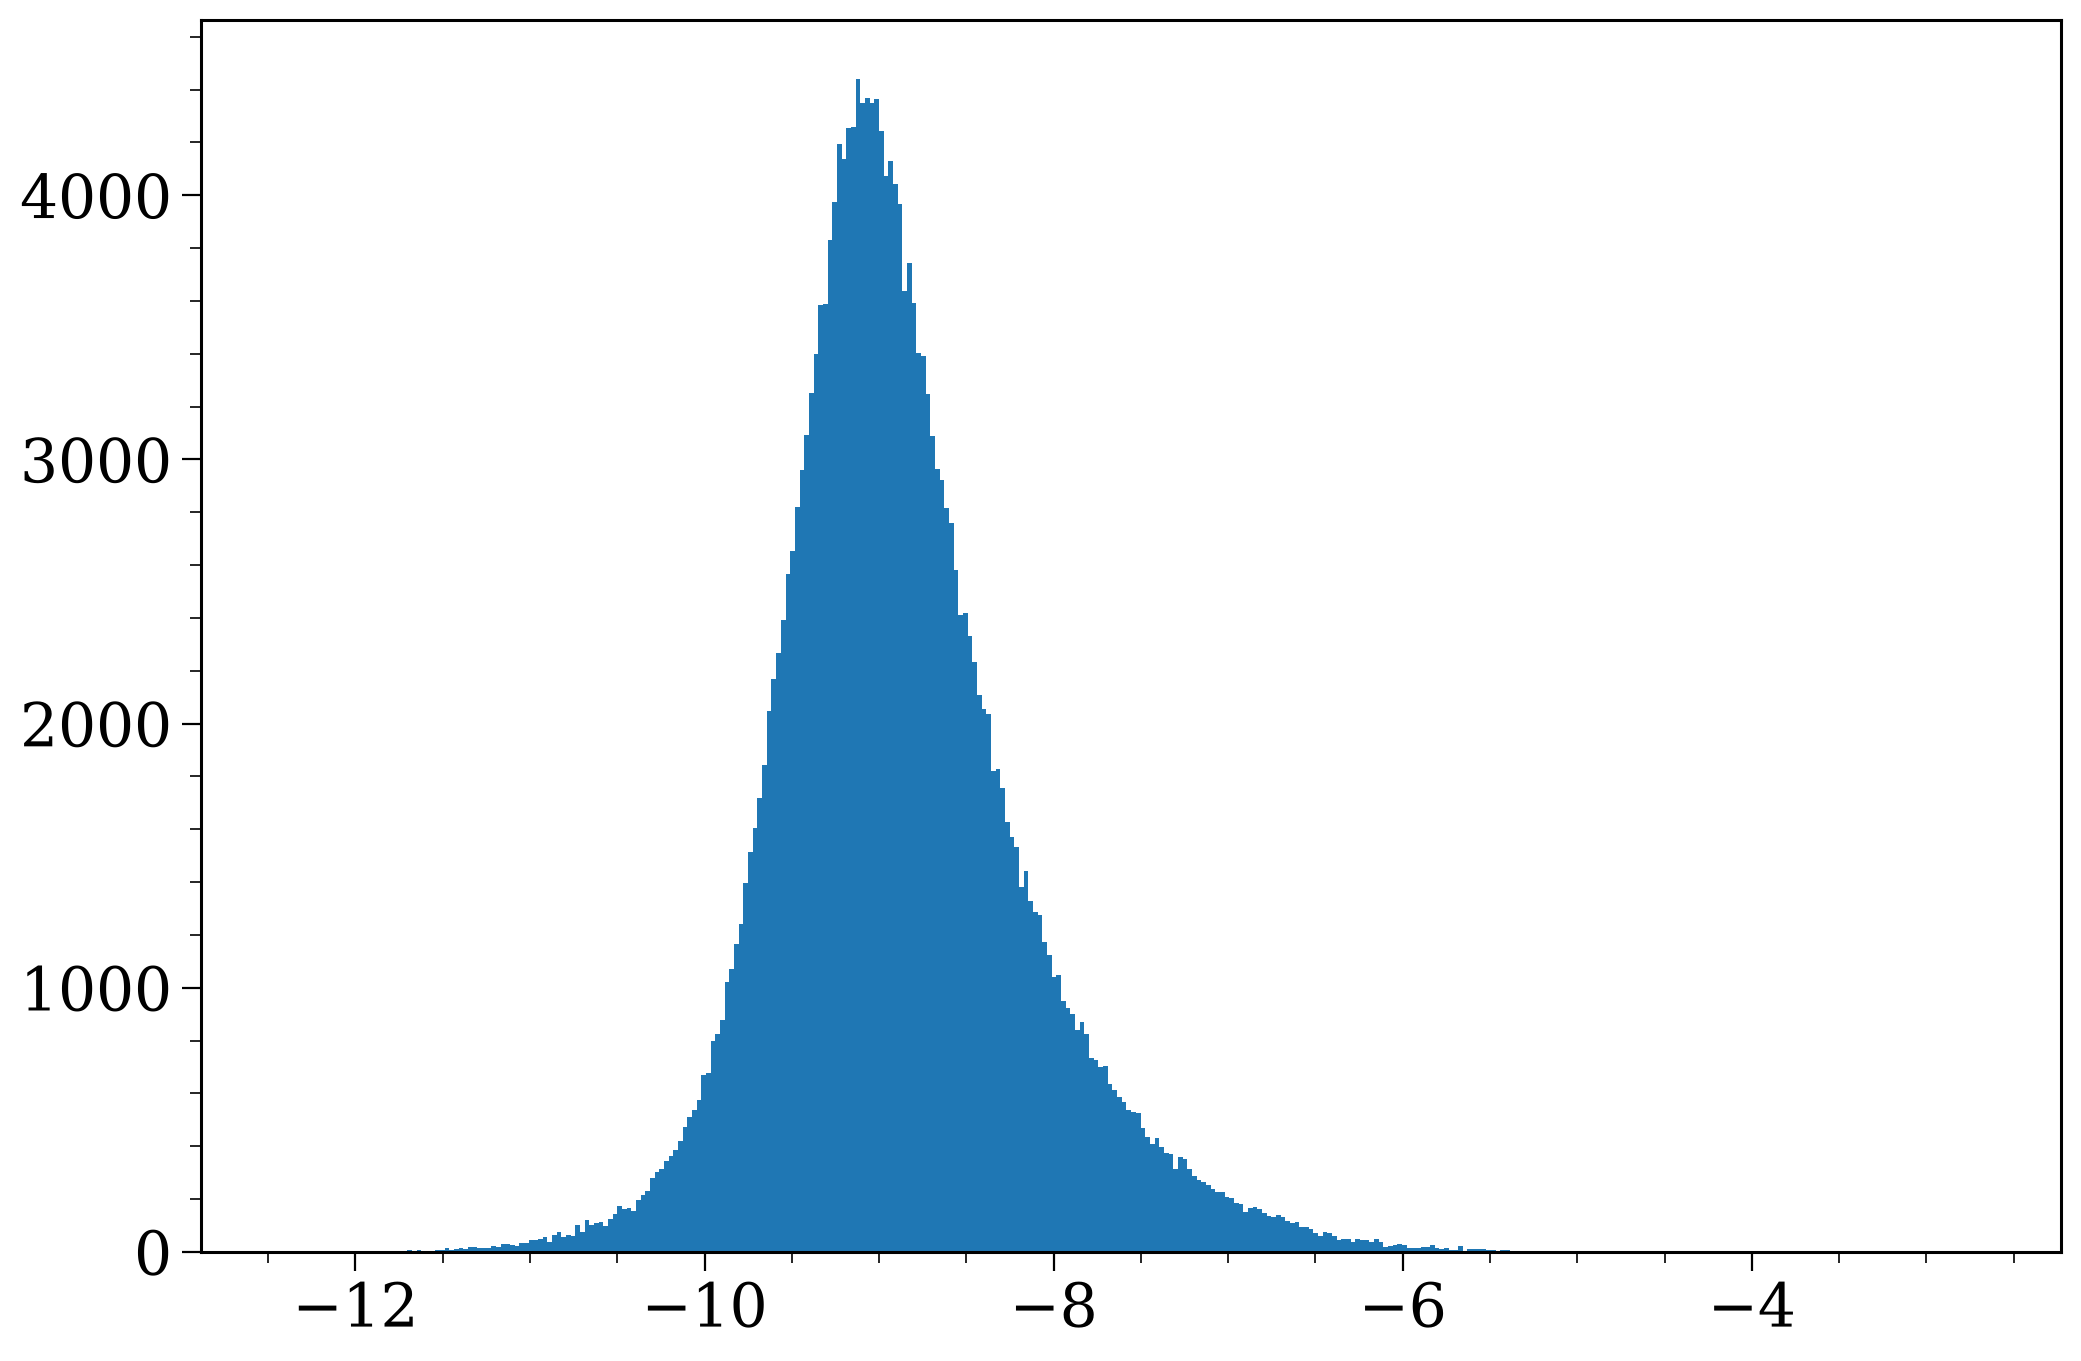

In [21]:
plt.hist(np.log10(np.abs(lw.utils.fn_dot(lisa_sources["NSWD"].m_c, lisa_sources["NSWD"].f_orb, lisa_sources["NSWD"].ecc, 2).value)), bins="fd")

In [18]:
lisa_sources["NSWD"]

<Source: 225066 sources>

In [36]:
unc.get_f_orb_dot_uncertainty

<function uncertainties.get_f_orb_dot_uncertainty(snr, t_obs, f_orb_dot)>

In [71]:
((-f_orb_dots_neg.values * u.Hz / u.yr) * 8 * u.yr / rlof_sources["NSWD"].f_orb[mask]).max()

<Quantity 0.00312625>

[0.16031932 0.82690283 3.89207598] 2322.755484244033
1.0 fraction with uncertainty < 100


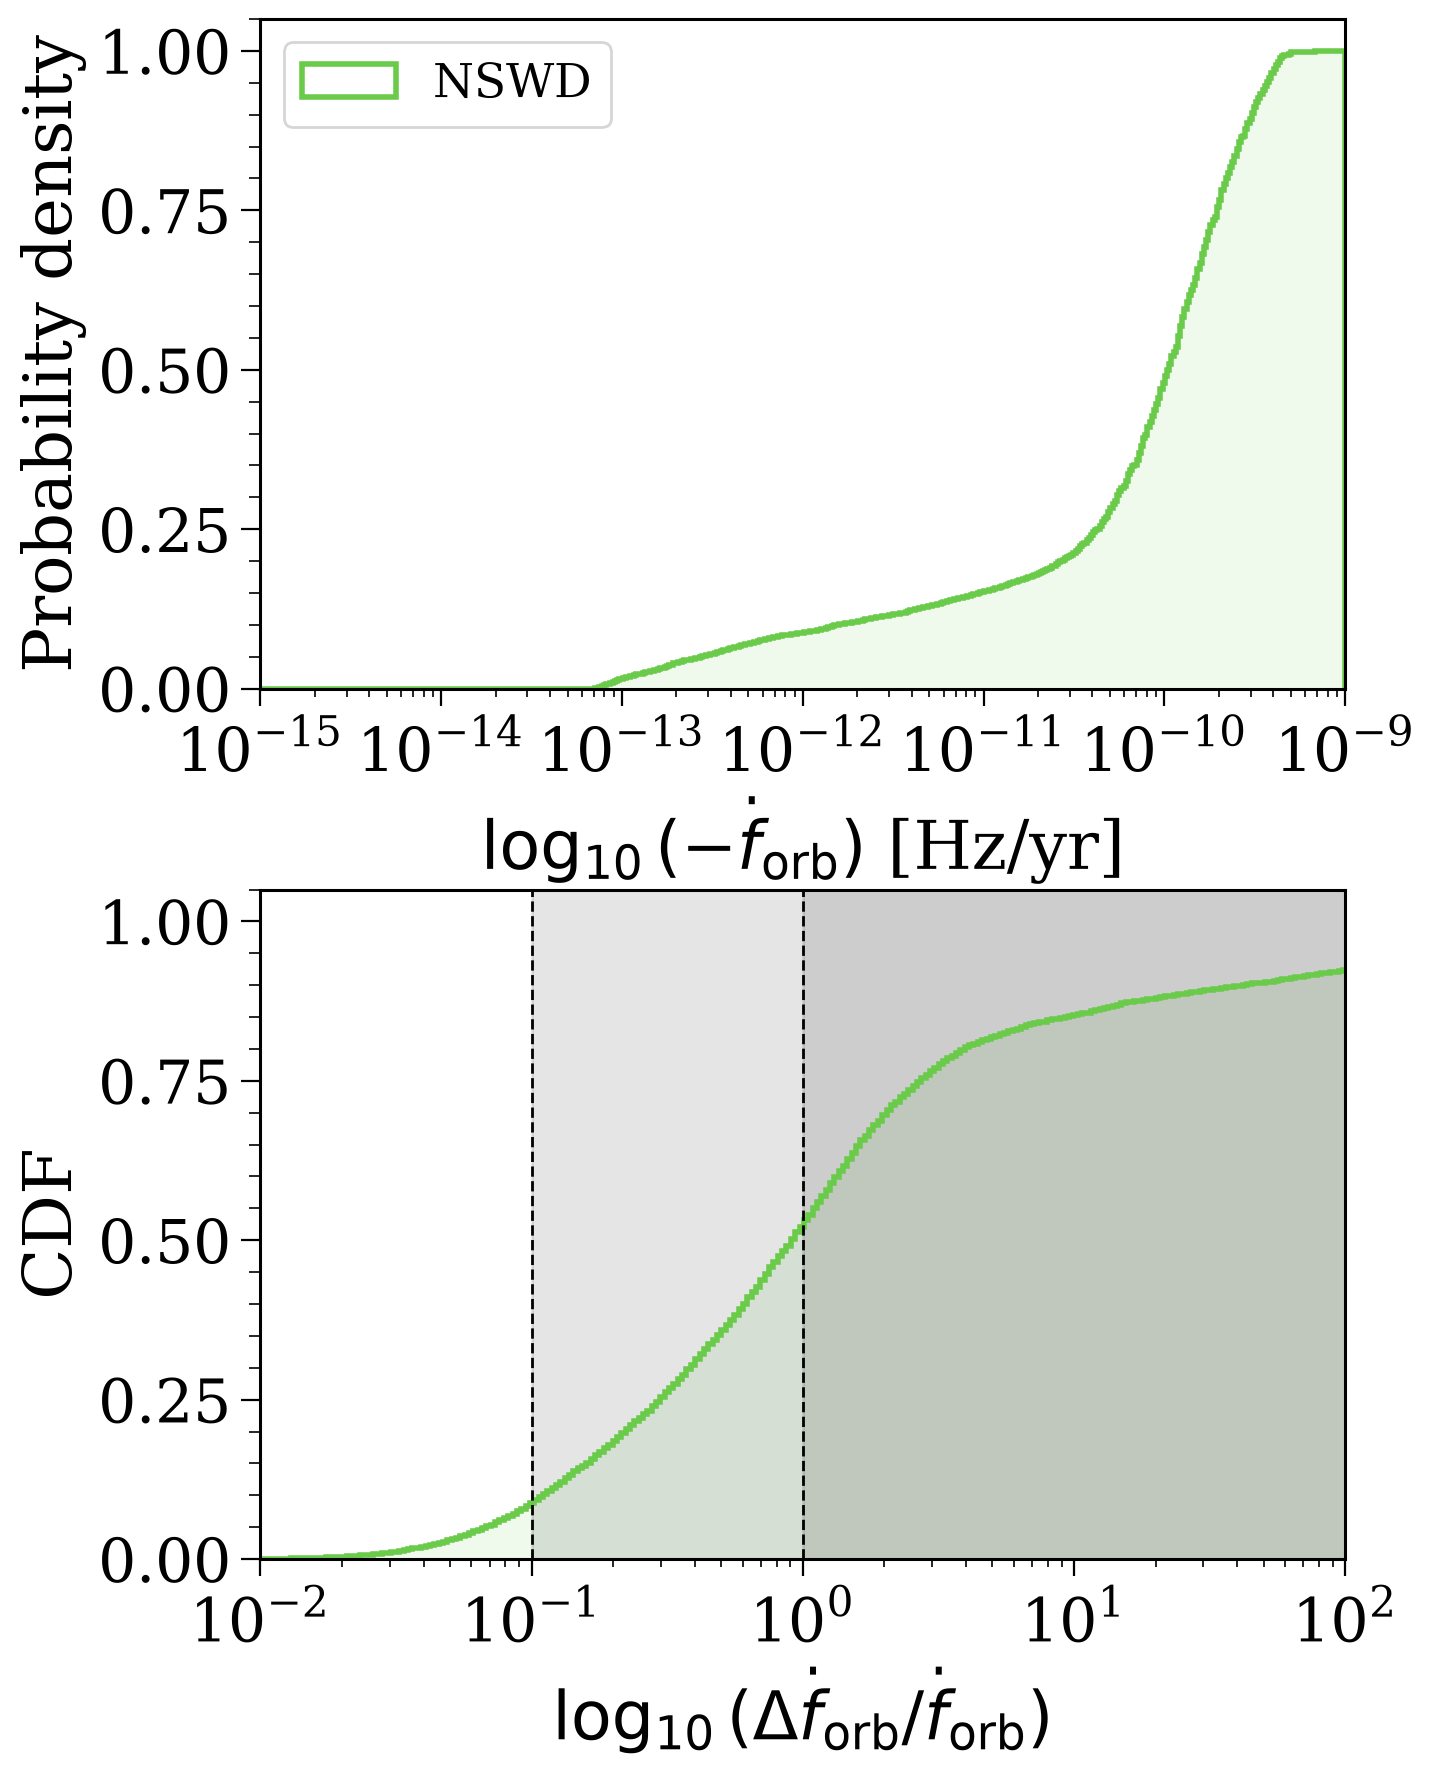

In [59]:
fig, axes = plt.subplots(2, 1, figsize=(7, 10))

fig.subplots_adjust(hspace=0.3)

for dco_type, kstar_1 in zip(["NSWD", "BHWD"], [13, 14]):

    bcm = bcms[dco_type]
    dco_rows = bcm[(bcm["kstar_1"] == kstar_1) & (bcm["kstar_2"].isin([10, 11, 12]))]
    dco_rows["f_orb"] = 1 / dco_rows["porb"].values
    f_orb_dot = np.zeros(len(dco_rows))
    f_orb_dot[1:] = (np.diff(dco_rows["f_orb"].values) / u.day / (np.diff(dco_rows["tphys"].values) * u.Myr)).to(u.Hz / (u.yr)).value
    dco_rows["f_orb_dot"] = f_orb_dot

    f_orb_dots = dco_rows.drop_duplicates(subset="bin_num", keep="last")["f_orb_dot"]
    f_orb_dots_neg = f_orb_dots[f_orb_dots < 0]

    mask = np.isin(rlof_pops[dco_type].bin_nums, dco_rows["bin_num"][f_orb_dots_neg.index])

    plotting.nice_transparent_hist(
        axes[0], np.log10(np.abs(f_orb_dots_neg)), weights=rlof_pops[dco_type].bpp["weights"].values[mask],
        label=dco_type, bins=np.linspace(-15, -9, 500), colour=const.DCO_COLOURS[dco_type],
        lw=2, density=True, alpha=0.1, cumulative=True
    )
    plotting.fake_log_axis(axes[0], axis="x")

    if rlof_sources[dco_type].snr is None:
        rlof_sources[dco_type].sc_params["t_obs"] = 8 * u.yr
        rlof_sources[dco_type].get_snr()
    f_orb_uncertainty = unc.get_f_orb_dot_uncertainty(
        rlof_sources[dco_type].snr[mask], 8 * u.yr, abs(f_orb_dots_neg.values) * u.Hz / u.yr
    )

    print(np.percentile(f_orb_uncertainty, [16, 50, 84]), np.max(f_orb_uncertainty))
    print((f_orb_uncertainty < 1e4).sum() / len(f_orb_uncertainty), "fraction with uncertainty < 100")

    plotting.nice_transparent_hist(
        axes[1], np.log10(f_orb_uncertainty), weights=rlof_pops[dco_type].bpp["weights"].values[mask],
        label=dco_type, bins=np.linspace(-2, 6, 500), colour=const.DCO_COLOURS[dco_type],
        lw=2, density=True, alpha=0.1, cumulative=True
    )
    plotting.fake_log_axis(axes[1], axis="x")

    break

lims = [-1, 0]
for lim in lims:
    axes[1].axvline(lim, color="k", ls="--", lw=1)
    axes[1].axvspan(lim, 2, color="k", alpha=0.1)

axes[0].legend()

axes[0].set(
    xlabel=r"$\log_{10}(-\dot{f}_{\rm orb})$ [Hz/yr]", ylabel="Probability density", xlim=(-15, -9)
)
axes[1].set(
    xlabel=r"$\log_{10}(\Delta \dot{f}_{\rm orb} / \dot{f}_{\rm orb})$", ylabel="CDF", xlim=(-2, 2)
)

plt.show()

In [55]:
(u.Hz/u.yr).to(u.yr**-2)

31557599.999999993

(array([3.94590340e+00, 8.23366401e+01, 5.03598370e+02, 8.33359268e+01,
        1.13329808e+00, 0.00000000e+00, 2.20905336e-01, 5.46398917e-01,
        1.82873866e+00, 1.02064211e+00]),
 array([-11.40281531,  -9.40731756,  -7.41181981,  -5.41632206,
         -3.42082431,  -1.42532656,   0.57017119,   2.56566894,
          4.56116669,   6.55666444,   8.55216219]),
 [<matplotlib.patches.Polygon at 0x1540eb757740>])

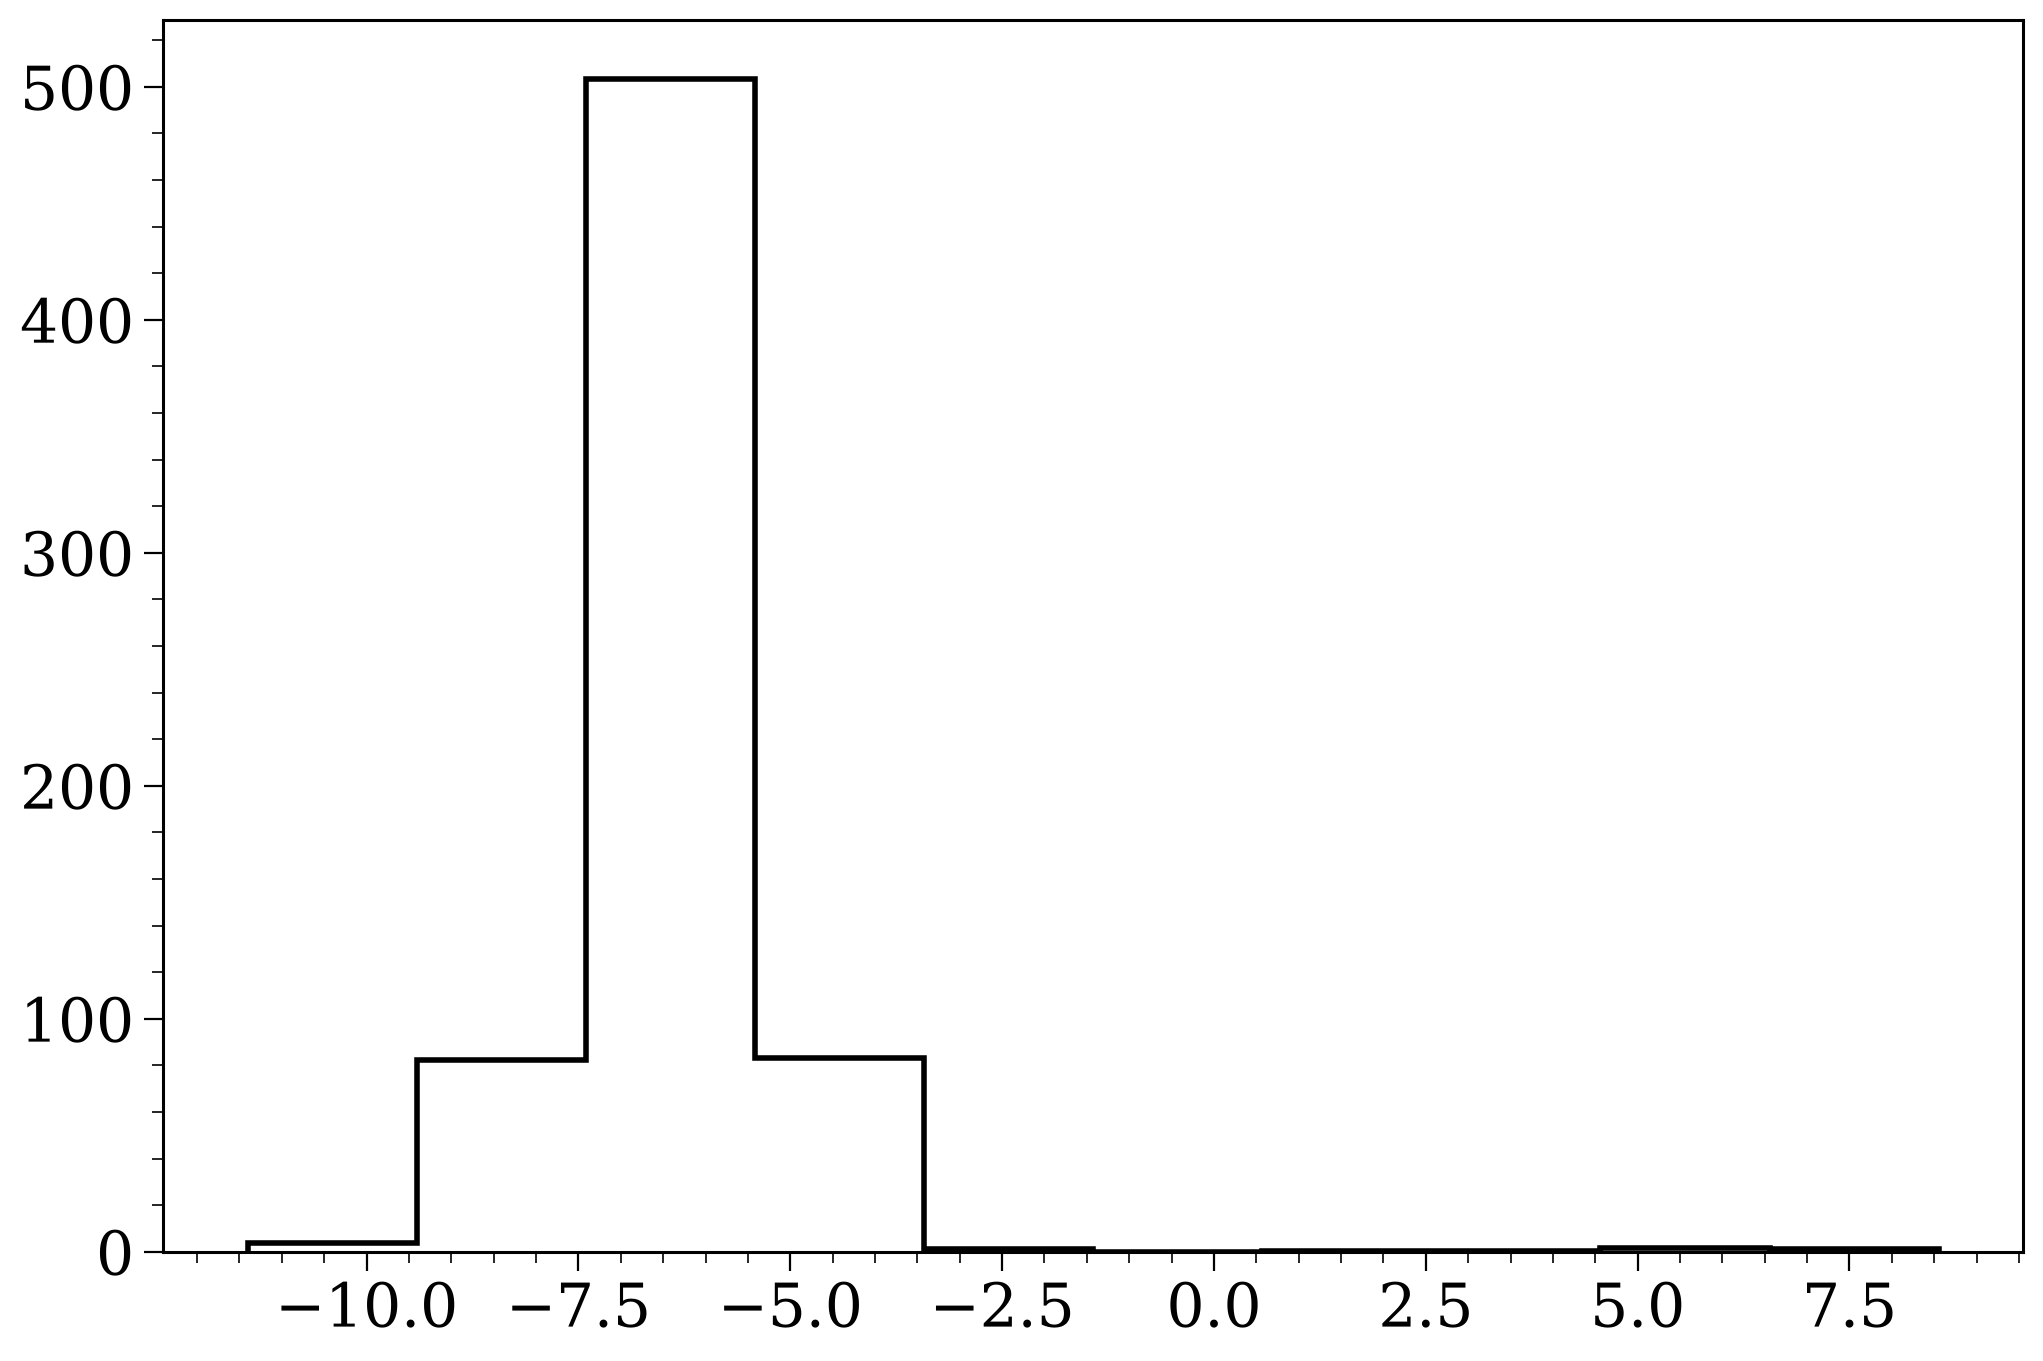

In [287]:
mask = np.isin(rlof_pops["BHWD"].bin_nums, dco_rows["bin_num"][f_orb_dots_neg.index])
plt.hist(np.log10(np.abs(unc.get_f_orb_dot_uncertainty(rlof_sources["BHWD"][mask].get_snr(), 8 * u.yr, f_orb_dots_neg.values / u.day**2))), weights=rlof_pops["BHWD"].bpp["weights"].values[mask], histtype="step", color="k", lw=2)


7.999956708250264e-08


<Quantity -6.40431322e-11 Hz / s>

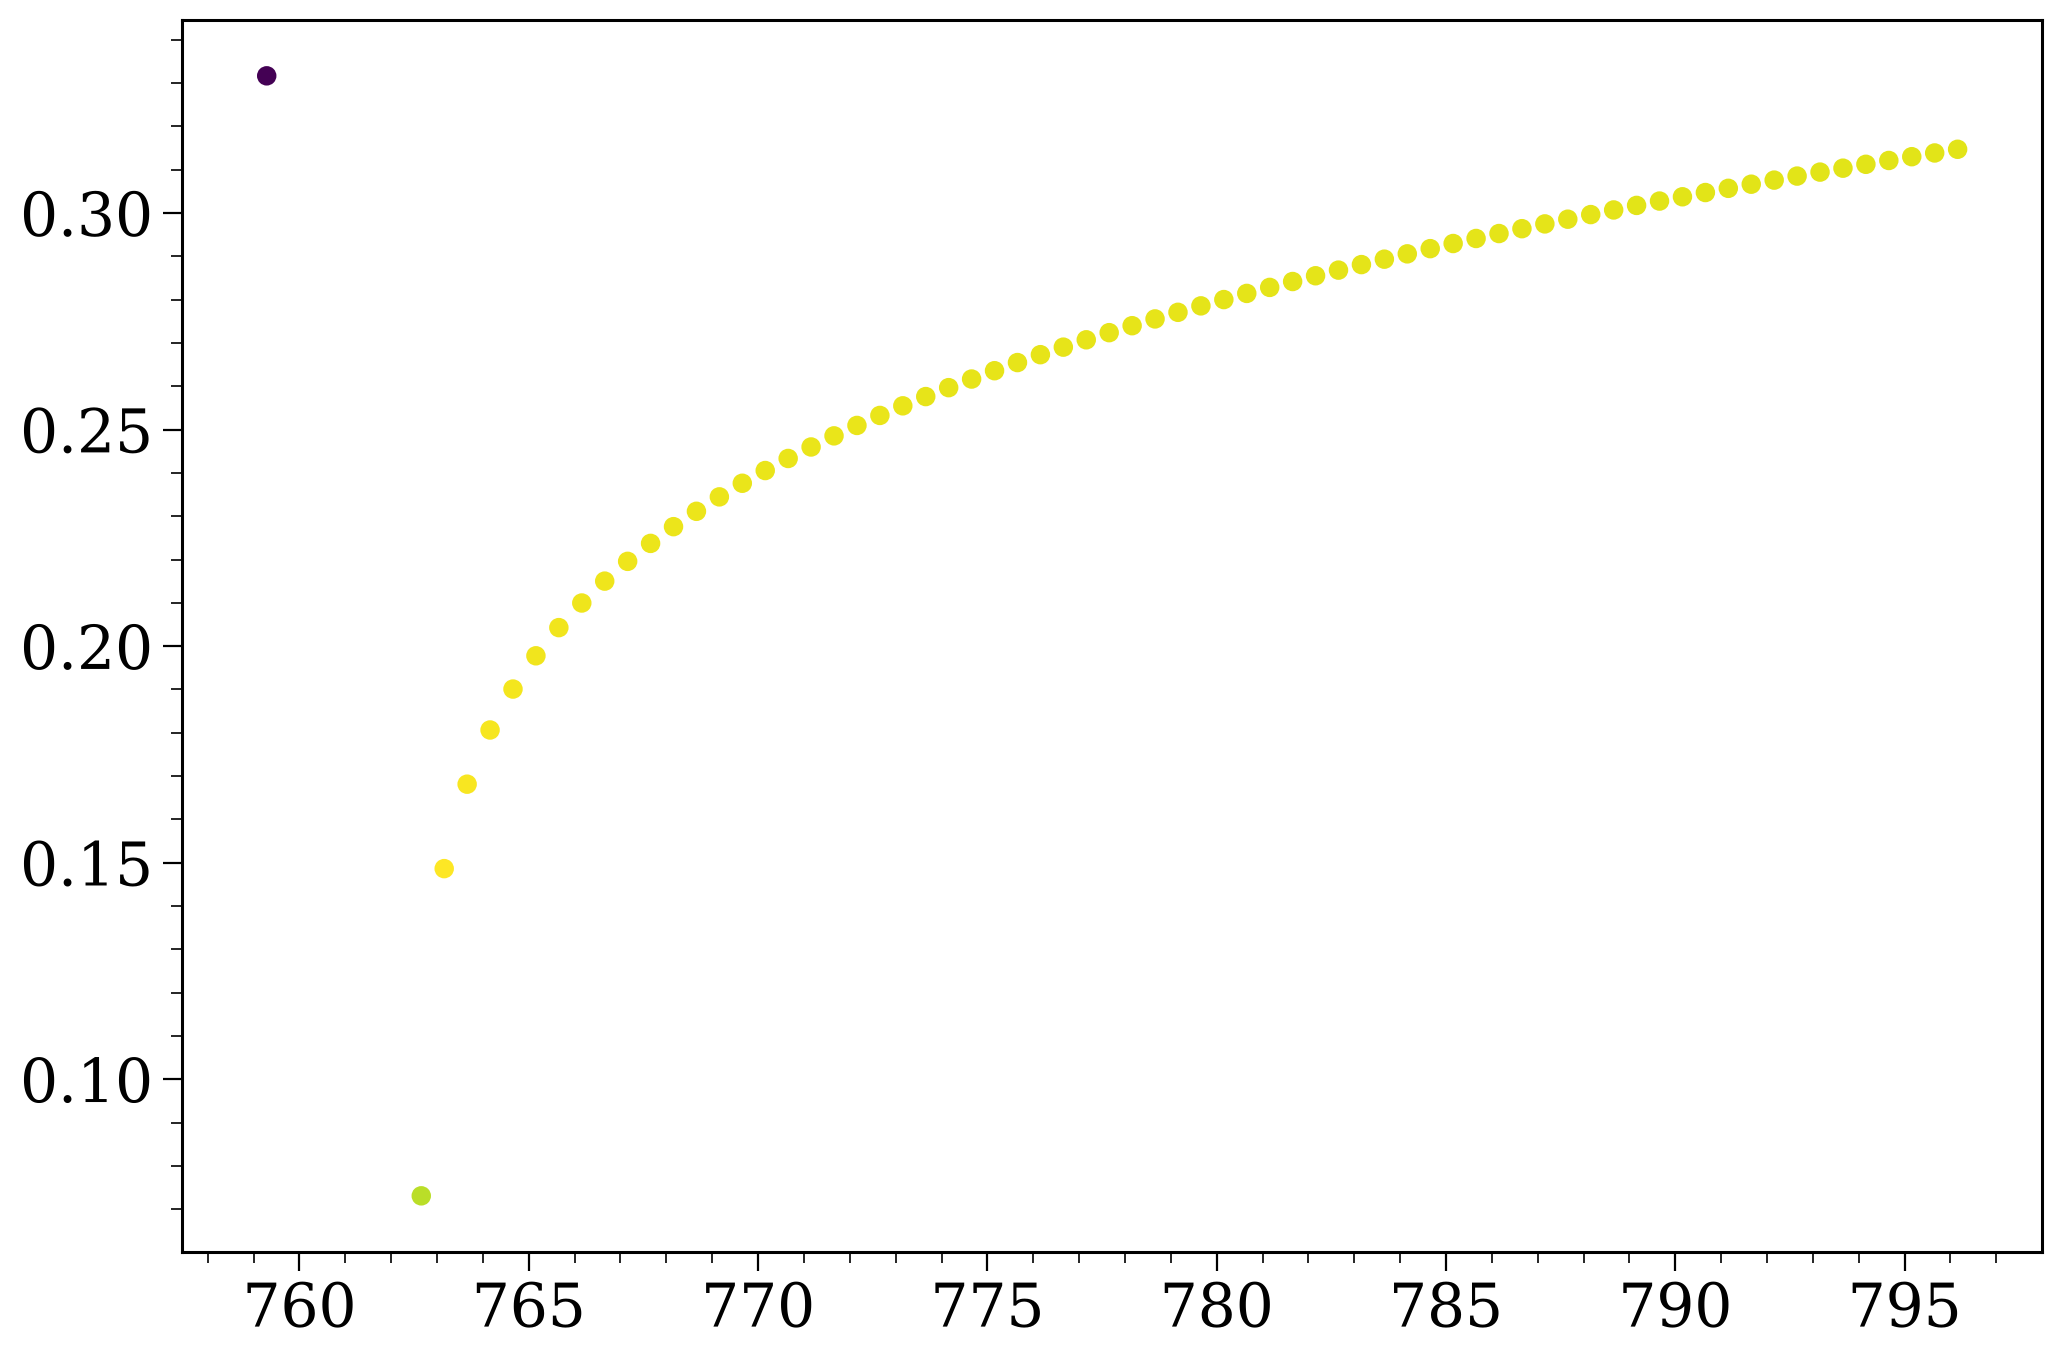

In [210]:
IND = 10
uni_bns = bcm.index.unique()
bcm_rows = bcm.loc[bcm.index.unique()[IND]]
bcm_rows = bcm_rows[(bcm_rows["kstar_1"] == 13) & (bcm_rows["kstar_2"].isin([10, 11, 12]))]
# plt.plot(bcm_rows["tphys"], bcm_rows["sep"], label="sep", marker='o', markerfacecolor=bcm_rows["RRLO_2"].values)
plt.scatter(bcm_rows["tphys"], bcm_rows["sep"], label="sep", marker='o', c=bcm_rows["RRLO_2"].values)
# work out the change in separation as a function of time in the final rows
bcm_rows["f_orb"] = 1 / bcm_rows["porb"]
f_orb_dot = np.diff(bcm_rows["f_orb"].values) / u.day / (np.diff(bcm_rows["tphys"].values) * u.day)
snr = rlof_pops["NSWD"].bpp["snr_lisa_8yr_final_pos"].values[IND]
print(unc.get_f_orb_dot_uncertainty(snr, 8 * u.yr, abs(f_orb_dot[-1].to(u.Hz / u.s))))
f_orb_dot[-1].to(u.Hz / u.s)

In [33]:
initC["tphysf"]

501673        13700.0
506388        13700.0
506778        13700.0
509612        13700.0
511721        13700.0
               ...   
2539301113    13700.0
2539321685    13700.0
2539341419    13700.0
2539357001    13700.0
2539359078    13700.0
Name: tphysf, Length: 145559, dtype: float64

In [16]:
lisa_pops["NSWD"].bpp

,tphys,mass_1,mass_2,kstar_1,kstar_2,sep,ecc,bin_num,weights,remove_if_pessimistic,rlof_time,rlof_sep,evol_type,sep_present_day,ecc_present_day,snr_lisa_8yr_initial_pos,snr_lisa_4yr_initial_pos,snr_lisa_8yr_final_pos,snr_lisa_4yr_final_pos,snr_decigo_8yr_initial_pos,snr_decigo_4yr_initial_pos,snr_decigo_8yr_final_pos,snr_decigo_4yr_final_pos,MW_instance
2409,1190.453165,1.277644,0.268821,13,10,0.857754,0.0,2409,0.026625,False,1353.954528,0.074414,15,0.212994,0.0,21.242527,12.978168,12.556729,7.671561,36.594278,18.262299,21.631345,10.795078,0
5314,867.262046,1.277607,0.306405,13,10,0.974700,0.0,5314,0.031950,False,1101.013224,0.067950,15,0.227855,0.0,16.697964,9.325185,38.925826,21.738610,25.569014,11.635944,59.605771,27.125388,0
12093,1299.293356,1.277653,0.262095,13,10,1.125407,0.0,12093,0.059135,False,1799.547913,0.075728,15,0.402828,0.0,1.047435,0.680499,14.293826,9.286432,0.000000,0.000000,0.000000,0.000000,0
14137,127.272731,2.295627,0.531034,13,11,2.415082,0.0,14137,0.035850,False,NaN,NaN,15,0.376985,0.0,10.820300,6.137822,54.951241,31.171126,12.006777,6.546299,60.976799,33.245591,0
15683,702.976844,2.051903,0.287223,13,10,0.886988,0.0,15683,0.019034,False,775.131404,0.081141,15,0.405024,0.0,4.628719,2.854295,27.609914,17.025624,5.047048,3.044153,30.105208,18.158111,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2539301113,10876.867770,1.354446,0.063360,13,10,0.181867,0.0,2539301113,0.019574,False,10874.716864,0.093763,10,0.181867,0.0,51.837018,35.876921,12.726929,8.808435,111.330265,71.801807,27.333601,17.628647,2589
2539321685,10312.269223,1.321792,0.098367,13,10,0.133209,0.0,2539321685,0.026158,False,10310.172877,0.078730,10,0.133209,0.0,37.856881,26.768778,37.584651,26.576283,152.534650,107.853104,151.437769,107.077529,2589
2539341419,10018.834010,1.391070,0.063076,13,10,0.183823,0.0,2539341419,0.036307,False,10015.533009,0.071730,10,0.183823,0.0,14.409939,9.963786,25.222381,17.440074,30.837899,19.825646,53.976997,34.701743,2589
2539357001,10296.131087,1.281984,0.217299,13,10,0.238930,0.0,2539357001,0.059505,False,10296.078696,0.086068,10,0.238930,0.0,22.393220,11.638454,14.619932,7.598434,30.364824,13.406992,19.824378,8.753065,2589
